# Phase 2 — 2D Spatial Dynamics: Diffusion, the Poisson Problem and Cavity Flow

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/phase2_spatial.ipynb)

*An overview of the 2D steps of the series, moved from somax's tutorial series.*

Two dimensions add a qualitatively new ingredient that [1D fundamentals](phase1_fundamentals.ipynb) could not show: an elliptic constraint. An incompressible flow cannot evolve its vorticity without solving a Poisson equation for the streamfunction at every step, a global, instantaneous coupling with no time step of its own. This page builds up to that coupling through 2D diffusion, the Poisson solve in isolation and finally the lid-driven cavity, where advection, diffusion and the elliptic inversion all act together {cite}`durran2010numerical,cushman2011introduction`.

**What you'll learn:**

1. How diffusion smooths a 2D field on the staggered grid
2. Why incompressible dynamics needs an elliptic (Poisson) solve, and what its solution looks like
3. How the vorticity–streamfunction Navier–Stokes model assembles advection, diffusion and the Poisson solve into the cavity benchmark

### Symbols

Everything is nondimensional, and $(x, y)$ are the spatial coordinates.

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $(x, y) \in [0, L_x] \times [0, L_y]$ | spatial coordinates | $\mathbb{R}^2$ |
| $t$ | time | $\mathbb{R}$ |
| $u_d(x, y, t)$ | the diffusing field | $\mathbb{R}$ |
| $\omega(x, y, t)$ | vorticity | $\mathbb{R}$ |
| $\psi(x, y, t)$ | streamfunction | $\mathbb{R}$ |
| $u = \partial \psi / \partial y$, $v = -\partial \psi / \partial x$ | velocity components | $\mathbb{R}$ |
| $\nu$ | viscosity | $\mathbb{R}_{>0}$ |
| $\sigma_0$ | initial Gaussian width | $\mathbb{R}_{>0}$ |
| $u_\text{lid}$, $\mathrm{Re} = u_\text{lid} L_x / \nu$ | lid speed and Reynolds number | $\mathbb{R}$, $\mathbb{R}_{>0}$ |
| $N_{\Omega_x,x}$, $N_{\Omega_x,y}$ | number of interior cells along $x$ and $y$ | count |
| $N_T$ | number of saved snapshots | count |
| $\Delta x$, $\Delta y$, $\Delta t$ | grid spacings and time step | $\mathbb{R}_{>0}$ |

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

In [2]:
import diffrax as dfx
import einx
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Two-dimensional diffusion

The 2D diffusion equation smooths a field isotropically,

$$\frac{\partial u_d}{\partial t} = \nu \nabla^2 u_d = \nu \left(\frac{\partial^2 u_d}{\partial x^2} + \frac{\partial^2 u_d}{\partial y^2}\right)$$ (p2-diffusion)

and inherits the parabolic step limit from one dimension in a slightly stricter form, $\nu \Delta t (\Delta x^{-2} + \Delta y^{-2}) \le 1/2$. A compact Gaussian blob of width $\sigma_0$ relaxes into a wider, flatter mound with peak $\sigma_0^2 / (\sigma_0^2 + 2 \nu t)$ while conserving its integral. [Step 7](step07_diffusion_2d.ipynb) works through this model in detail.

In [4]:
# Shapes: N_Ωx,x = N_Ωx,y = 96 interior cells; N_T = 2 saved snapshots;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

inner = slice(1, -1)
interior = (inner, inner)
blob_width = 0.05
viscosity = 2.0e-3
diffusion_end = 8.0

# today (sesmax_core)
diffusion_model = sxt.Diffusion2D.create(nx=96, ny=96, Lx=1.0, Ly=1.0, nu=viscosity)

# xᵢ = i Δx
x_position = jnp.arange(diffusion_model.grid.Nx) * diffusion_model.grid.dx
# yⱼ = j Δy
y_position = jnp.arange(diffusion_model.grid.Ny) * diffusion_model.grid.dy
# (xᵢ, yⱼ) on every cell
x_grid, y_grid = jnp.meshgrid(x_position, y_position)  # → G each
# r² = ((x − μₓ)² + (y − μ_y)²) / σ₀²
radius_squared = ((x_grid - 0.5) ** 2 + (y_grid - 0.5) ** 2) / blob_width**2  # → G
# u_d(x, y, 0) = exp(−r² / 2)
initial_blob = jnp.exp(-0.5 * radius_squared)  # → G
# today (sesmax_core)
blob_state = sxt.Diffusion2DState(u=initial_blob)
blob_state = diffusion_model.apply_boundary_conditions(blob_state)

# today (sesmax_core, diffrax)
blob_solution = diffusion_model.integrate(  # u → N_T × G
    blob_state,
    t0=0.0,
    t1=diffusion_end,
    dt=2.0e-3,
    saveat=dfx.SaveAt(ts=jnp.array([0.0, diffusion_end])),
    max_steps=20_000,
)
interior_blob = blob_solution.ys.u[:, *interior]  # → N_T × N_Ωx,y × N_Ωx,x

# ∑ᵢⱼ u_d Δx Δy over the interior cells, for each saved time
cell_area = diffusion_model.grid.dx * diffusion_model.grid.dy  # → ()
blob_area = einx.sum("t [y x] -> t", interior_blob) * cell_area  # → (N_T,)
# σ₀² / (σ₀² + 2νt)
exact_peak = blob_width**2 / (blob_width**2 + 2.0 * viscosity * diffusion_end)  # → ()
print(f"Area at t = 0: {float(blob_area[0]):.6f}, at t = 8: {float(blob_area[-1]):.6f}")
print(f"Peak at t = 8: {float(jnp.max(interior_blob[-1])):.4f}, exact {exact_peak:.4f}")

Area at t = 0: 0.015708, at t = 8: 0.015708
Peak at t = 8: 0.0725, exact 0.0725


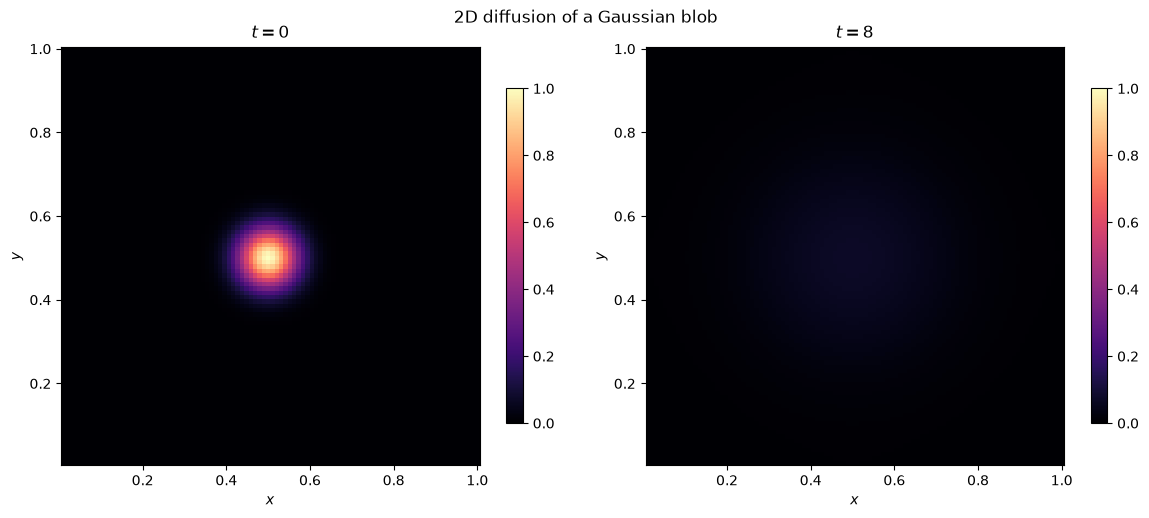

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, field, label in zip(axes, interior_blob, ["$t=0$", "$t=8$"], strict=True):
    pcm = ax.pcolormesh(
        x_grid[interior], y_grid[interior], field, cmap="magma", vmin=0.0, vmax=1.0
    )
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.set_title(label)
    ax.set_aspect("equal")
    plt.colorbar(pcm, ax=ax, shrink=0.8)
plt.suptitle("2D diffusion of a Gaussian blob")
plt.tight_layout()
plt.show()

The peak collapses and the support broadens isotropically, and the printed area stays the same.

## 2. The Poisson problem: the elliptic heart of incompressible flow

An incompressible 2D flow is divergence-free, so it derives from a streamfunction $\psi$ with $u = \partial \psi / \partial y$ and $v = -\partial \psi / \partial x$. Its vorticity $\omega = \partial v / \partial x - \partial u / \partial y$ then satisfies a Poisson equation,

$$\nabla^2 \psi = -\omega$$ (p2-poisson)

which must be solved globally and instantaneously to recover the velocity from the vorticity at every time step. Unlike advection or diffusion, {eq}`p2-poisson` has no time derivative: it is an elliptic constraint, and its fast, accurate inversion is the workhorse behind both the cavity below and the quasi-geostrophic ocean models. sesmax exposes the inversion directly as `PoissonSolver2D`, covered in [Step 10](step10_poisson_2d.ipynb).

In [6]:
# Shapes: N_Ωx,x = N_Ωx,y = 128 interior cells;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

# today (sesmax_core)
poisson_solver = sxt.PoissonSolver2D.create(
    nx=128, ny=128, Lx=1.0, Ly=1.0, bc="dirichlet"
)

# xᵢ = i Δx
x_position = jnp.arange(poisson_solver.grid.Nx) * poisson_solver.grid.dx
# yⱼ = j Δy
y_position = jnp.arange(poisson_solver.grid.Ny) * poisson_solver.grid.dy
# (xᵢ, yⱼ) on every cell
x_grid, y_grid = jnp.meshgrid(x_position, y_position)  # → G each
# r₊² = (x − 0.35)² + (y − 0.5)²
radius_positive = (x_grid - 0.35) ** 2 + (y_grid - 0.5) ** 2  # → G
# r₋² = (x − 0.65)² + (y − 0.5)²
radius_negative = (x_grid - 0.65) ** 2 + (y_grid - 0.5) ** 2  # → G
# ω = exp(−r₊² / 0.01) − exp(−r₋² / 0.01)
vortex_pair = jnp.exp(-radius_positive / 0.01) - jnp.exp(-radius_negative / 0.01)

# today (sesmax_core)
# ∇²ψ = −ω with ψ = 0 on the walls
pair_streamfunction = poisson_solver.solve(-vortex_pair)  # → G

# ψ on the nodes 0 … N_Ωx, walls included; the last row and column are ghosts
nodes = (slice(0, poisson_solver.grid.Ny - 1), slice(0, poisson_solver.grid.Nx - 1))
print(f"Streamfunction shape: {pair_streamfunction.shape}")
print(f"Finite: {bool(jnp.all(jnp.isfinite(pair_streamfunction)))}")
print(f"Largest |psi|: {float(jnp.max(jnp.abs(pair_streamfunction))):.4f}")

Streamfunction shape: (130, 130)
Finite: True
Largest |psi|: 0.0063


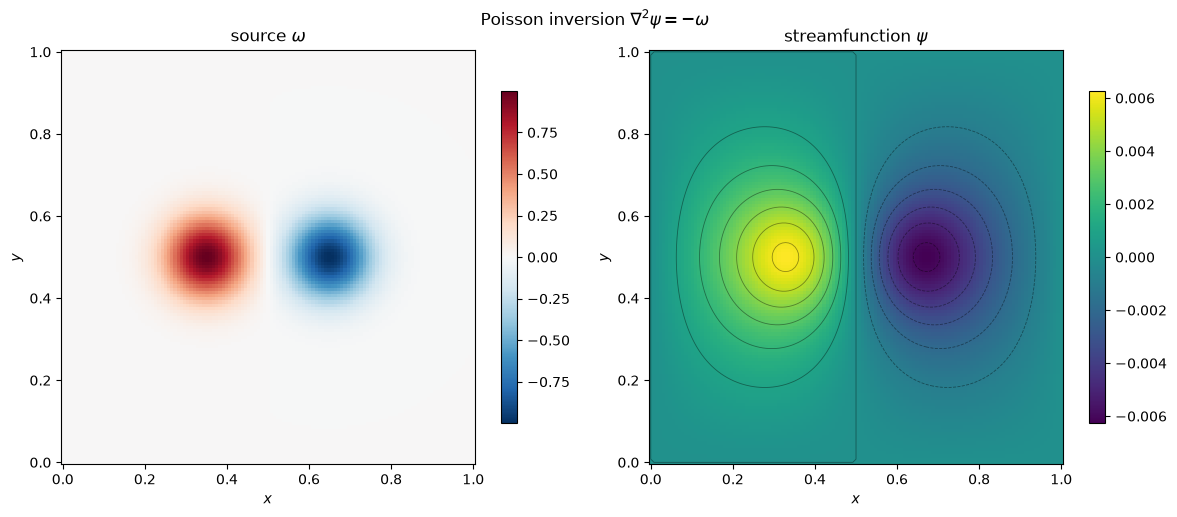

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
pcm = axes[0].pcolormesh(
    x_grid[nodes], y_grid[nodes], vortex_pair[nodes], cmap="RdBu_r"
)
axes[0].set_title(r"source $\omega$")
plt.colorbar(pcm, ax=axes[0], shrink=0.8)
pcm = axes[1].pcolormesh(
    x_grid[nodes], y_grid[nodes], pair_streamfunction[nodes], cmap="viridis"
)
axes[1].contour(
    x_grid[nodes],
    y_grid[nodes],
    pair_streamfunction[nodes],
    levels=12,
    colors="k",
    alpha=0.4,
    linewidths=0.6,
)
axes[1].set_title(r"streamfunction $\psi$")
plt.colorbar(pcm, ax=axes[1], shrink=0.8)
for ax in axes:
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.set_aspect("equal")
plt.suptitle(r"Poisson inversion $\nabla^2 \psi = -\omega$")
plt.tight_layout()
plt.show()

The left panel is a dipolar vorticity source, and the right panel is the streamfunction recovered by inverting {eq}`p2-poisson` with homogeneous Dirichlet boundaries. The closed $\psi$ contours are the streamlines of the vortex pair the source implies.

## 3. Lid-driven cavity: advection, diffusion and Poisson together

The lid-driven cavity is the standard benchmark that exercises all three ingredients at once. The vorticity transport equation

$$\frac{\partial \omega}{\partial t} + u \frac{\partial \omega}{\partial x} + v \frac{\partial \omega}{\partial y} = \nu \nabla^2 \omega$$ (p2-cavity)

is integrated in a square box whose top wall slides at constant speed while the other three are no-slip. Vorticity is generated at the moving lid, advected into the interior, diffused, and continuously re-inverted through {eq}`p2-poisson` to update the velocity. `IncompressibleNS2D` assembles exactly this loop, and [Step 12](step12_cavity_flow.ipynb) checks it against the Ghia et al. benchmark at $\mathrm{Re} = 100$. Here we run a higher Reynolds number from rest to $t = 5$, which is a developing flow rather than the steady state.

In [8]:
# Shapes: N_Ωx,x = N_Ωx,y = 96 interior cells;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

lid_speed = 1.0
cavity_viscosity = 2.0e-3

# today (sesmax_core)
cavity_model = sxt.IncompressibleNS2D.create(
    nx=96, ny=96, Lx=1.0, Ly=1.0, nu=cavity_viscosity, problem="cavity", u_lid=lid_speed
)
# ω = 0 at rest
rest_omega = jnp.zeros((cavity_model.grid.Ny, cavity_model.grid.Nx))  # → G
# today (sesmax_core)
rest_state = sxt.NSVorticityState(omega=rest_omega)
rest_state = cavity_model.apply_boundary_conditions(rest_state)

# today (sesmax_core, diffrax)
cavity_solution = cavity_model.integrate(  # ω → 1 × G
    rest_state, t0=0.0, t1=5.0, dt=2.5e-3, max_steps=20_000
)
# today (sesmax_core)
final_state = sxt.NSVorticityState(omega=cavity_solution.ys.omega[-1])
final_state = cavity_model.apply_boundary_conditions(final_state)
diagnostics = cavity_model.diagnose(final_state)

# Re = u_lid L_x / ν
reynolds_number = lid_speed * 1.0 / cavity_viscosity  # → ()
print(f"Re = {reynolds_number:.0f}")
print(f"Kinetic energy at t = 5: {float(diagnostics.kinetic_energy):.5f}")

Re = 500
Kinetic energy at t = 5: 0.02216


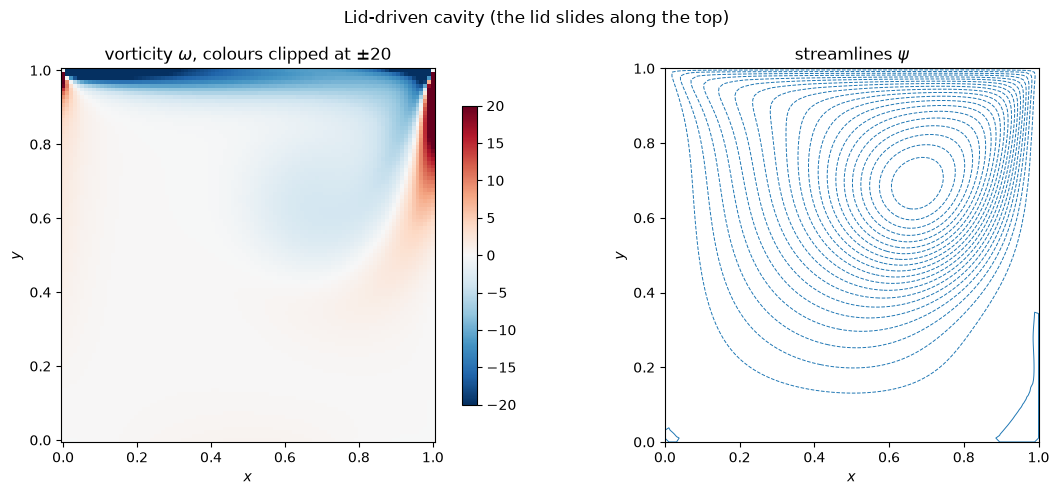

In [9]:
# ω and ψ on the nodes 0 … N_Ωx, walls included; the last row and column are ghosts
nodes = (slice(0, cavity_model.grid.Ny - 1), slice(0, cavity_model.grid.Nx - 1))
# xᵢ = i Δx
x_position = jnp.arange(cavity_model.grid.Nx) * cavity_model.grid.dx
# yⱼ = j Δy
y_position = jnp.arange(cavity_model.grid.Ny) * cavity_model.grid.dy
x_grid, y_grid = jnp.meshgrid(x_position, y_position)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
pcm = axes[0].pcolormesh(
    x_grid[nodes],
    y_grid[nodes],
    final_state.omega[nodes],
    cmap="RdBu_r",
    vmin=-20.0,
    vmax=20.0,
)
axes[0].set_title(r"vorticity $\omega$, colours clipped at $\pm 20$")
plt.colorbar(pcm, ax=axes[0], shrink=0.8)
axes[1].contour(
    x_grid[nodes],
    y_grid[nodes],
    diagnostics.psi[nodes],
    levels=20,
    colors="C0",
    linewidths=0.7,
)
axes[1].set_title(r"streamlines $\psi$")
for ax in axes:
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.set_aspect("equal")
plt.suptitle("Lid-driven cavity (the lid slides along the top)")
plt.tight_layout()
plt.show()

On the left, vorticity is generated at the sliding top wall and swept around the box. On the right, the streamlines from the Poisson inversion show the primary vortex that the lid drives.

## Summary

- 2D diffusion {eq}`p2-diffusion` smooths isotropically under a parabolic step limit, the direct extension of the 1D case.
- Incompressible flow carries an elliptic constraint: the Poisson equation {eq}`p2-poisson` must be inverted at every step to recover velocity from vorticity, a global coupling with no time step of its own, exposed as `PoissonSolver2D`.
- The lid-driven cavity {eq}`p2-cavity` welds advection, diffusion and the Poisson solve into one loop, and the same vorticity–streamfunction structure reappears in the quasi-geostrophic ocean models.

**Next:** Phase 3 turns to low-order chaos, the Lorenz systems.